In [9]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [10]:
proposal_number = 101927227  # noqa
run = 49  # noqa

In [11]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='/jungfrau1M/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay',
    measured_voltage='ai/ch04'
)

7375
7372


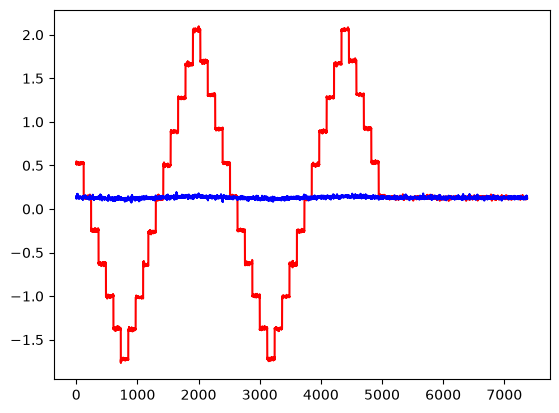

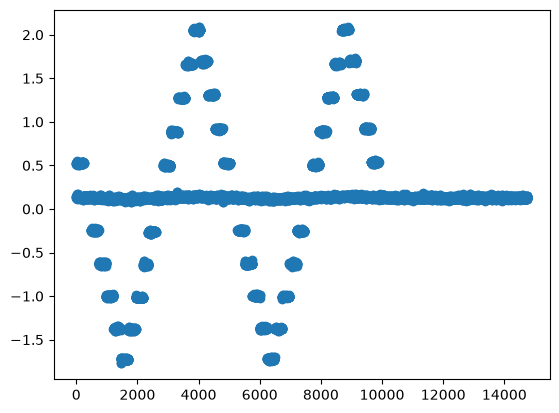

In [54]:
measured_voltage = h5[h5dict.measured_voltage][...]
laser_on = h5[h5dict.laser_on][...].astype(bool)
v_on = measured_voltage[laser_on]
v_off = measured_voltage[~laser_on]
print(len(v_on))
print(len(v_off))
plt.plot(v_on, label='on', color='red')
plt.plot(v_off, label='on', color='blue')
plt.show()
plt.plot(measured_voltage, linestyle=' ', marker='o')
plt.show()

In [12]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None)
valid = xcs.sensible_filter(metadata, 0.5, 99.5, 0.5, 99.5)

(14747, 8)
(7375, 8)
(7372, 8)


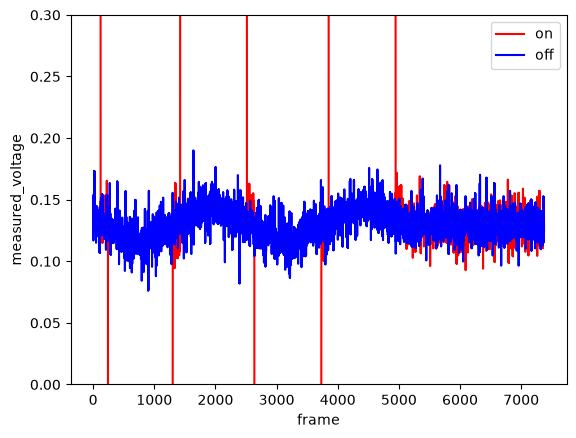

In [43]:
print(metadata.shape)
on_meta = metadata[metadata['laser_on']]
print(on_meta.shape)
off_meta = metadata[~metadata['laser_on']]
print(off_meta.shape)
plt.plot(on_meta['measured_voltage'].to_numpy(), label='on', color='red')
plt.plot(off_meta['measured_voltage'].to_numpy(), label='off', color='blue')
plt.xlabel('frame')
plt.ylabel('measured_voltage')
plt.ylim(bottom=0.0, top=0.3)
plt.legend()
plt.show()

In [15]:
rois = [
    (slice(70, 80), slice(185, 195)),
    (slice(70, 80), slice(165, 175))
]

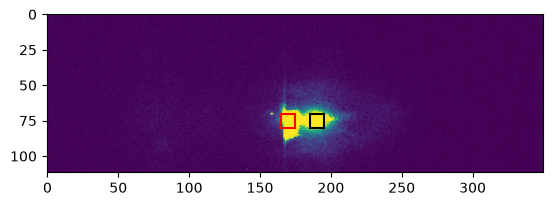

In [16]:
xcs.plot_detector_image(h5, h5dict, samplerate=100)
roi_colors = ['black', 'red']
for i, roi in enumerate(rois):
    plt.plot([roi[1].start, roi[1].stop], [roi[0].start, roi[0].start], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].stop], [roi[0].stop, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].start], [roi[0].start, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].stop, roi[1].stop], [roi[0].start, roi[0].stop], color=roi_colors[i])

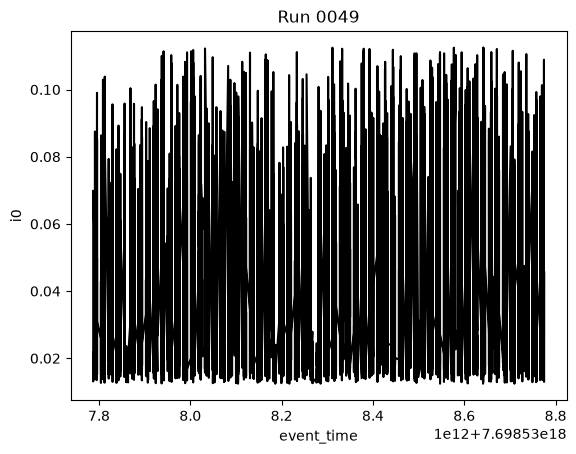

In [17]:
xcs.plot_i0_vs_time(metadata, valid).show()

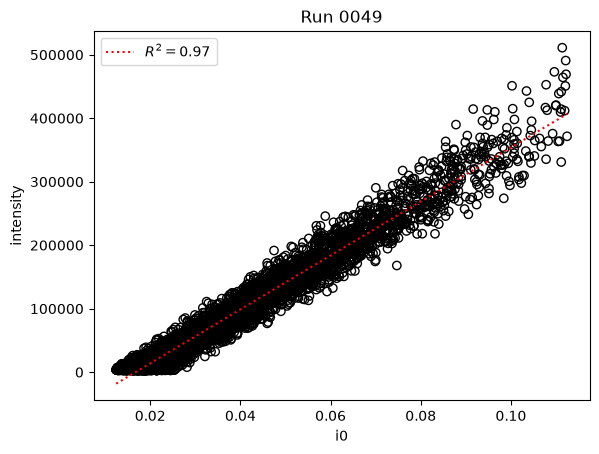

In [18]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

In [ ]:
xcs.plot_intensity_vs_time(metadata, valid).show()

In [19]:
metadata

,intensity_in_roi,shot_idx,event_time,laser_on,xray_on,i0,delay,measured_voltage
0,4531.623047,0,7698537787275445268,True,True,0.021668,689000.000043,0.520020
1,50389.207031,1,7698537787283760993,False,True,0.036240,689000.000043,0.133972
2,55810.917969,2,7698537787292076428,True,True,0.033875,689000.000043,0.529480
3,115848.281250,3,7698537787300453015,False,True,0.043870,689000.000043,0.131226
4,167196.140625,4,7698537787308794492,True,True,0.050126,689000.000043,0.520020
...,...,...,...,...,...,...,...,...
14742,3493.437256,14742,7698538774749460617,False,True,0.018158,989000.000060,0.115356
14743,64708.089844,14743,7698538774757925589,True,True,0.039292,989000.000060,0.128784
14744,6299.915039,14744,7698538774766161351,False,True,0.012284,989000.000060,0.133057
14745,112087.000000,14745,7698538774774506247,True,True,0.045472,989000.000060,0.124207


: = off.
- = on/off


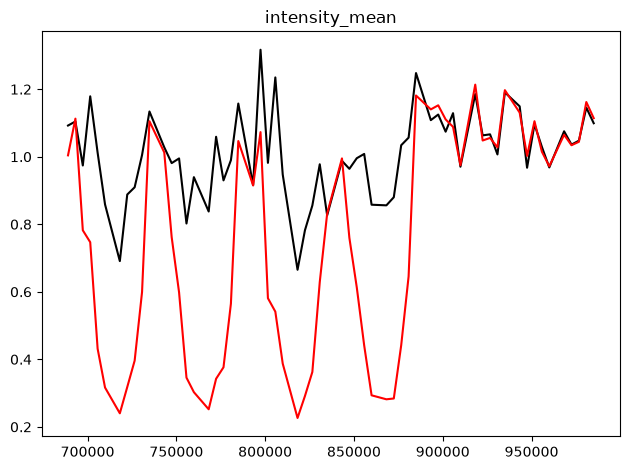

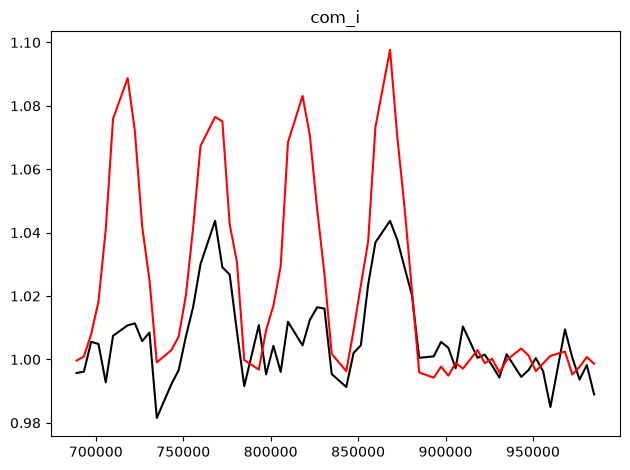

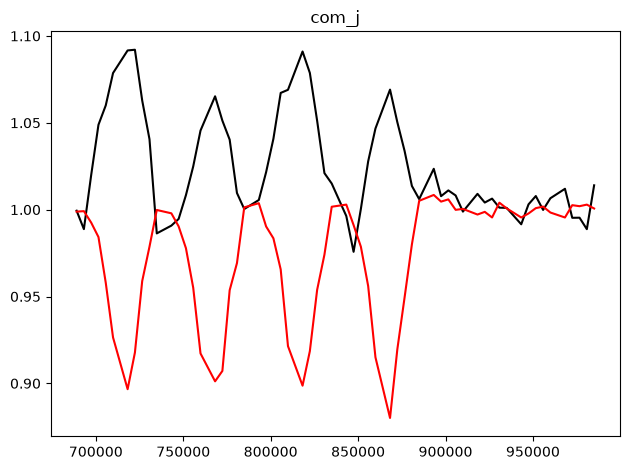

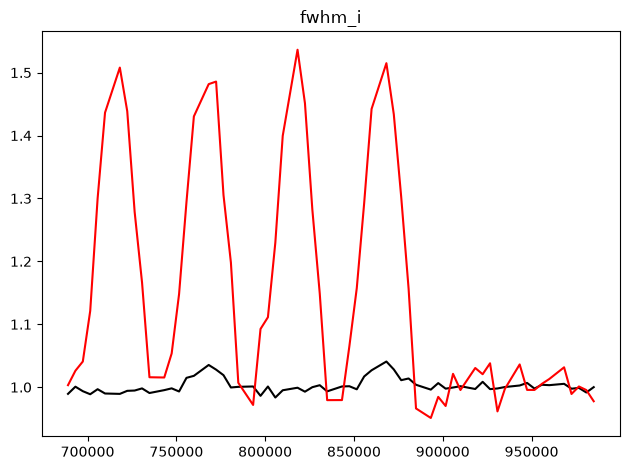

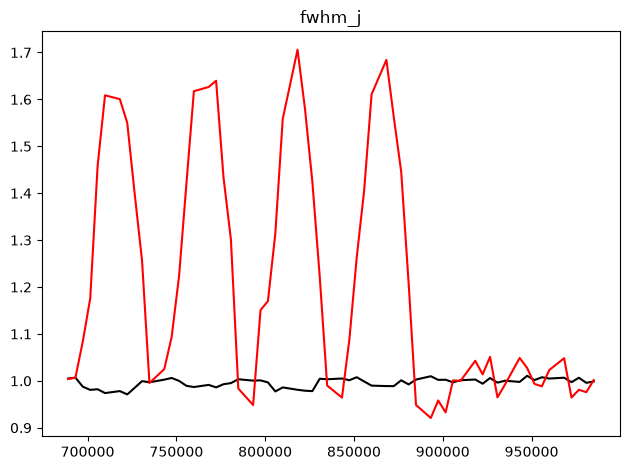

In [22]:

print(': = off.\n- = on/off')
for i, tag in enumerate(['intensity_mean', 'com_i', 'com_j', 'fwhm_i', 'fwhm_j']):
    fig, ax = plt.subplots(1, 1)
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, 4169, roi=roi)

        ax.plot(trxrd.index, trxrd[f'on_{tag}']/trxrd[f'off_{tag}'], color=color, linestyle='-')
    ax.set_title(tag)
    fig.tight_layout()
    plt.show()

In [21]:
trxrd

,on_intensity_mean,on_intensity_stderr,on_com_i,on_com_j,on_fwhm_i,on_fwhm_j,n_on_shots,off_intensity_mean,off_intensity_stderr,off_com_i,off_com_j,off_fwhm_i,off_fwhm_j,n_off_shots
delay_bin,,,,,,,,,,,,,,
689000.000043,1.599260e+06,106317.861771,4.071724,7.785379,2.588476,3.300386,241.0,1.509140e+06,113462.035713,4.070560,7.792376,2.550394,3.284659,202.0
697338.000043,1.075219e+06,79085.588854,4.111628,7.725688,2.683950,3.568424,243.0,1.411969e+06,120156.733317,4.062961,7.810141,2.502190,3.178573,200.0
705676.000043,4.935773e+05,43833.980607,4.266764,7.389426,3.311340,4.521115,234.0,1.371479e+06,146012.743019,4.028297,7.845736,2.415668,2.937100,202.0
714014.000043,4.325034e+05,40230.534249,4.425220,6.991272,3.820987,5.197610,112.0,1.800688e+06,200140.506905,4.064531,7.797252,2.533790,3.247497,99.0
722352.000043,6.137706e+05,42631.158703,4.278175,7.385249,3.312109,4.562002,230.0,1.700755e+06,139284.396618,4.060473,7.832982,2.460385,3.111562,200.0
730690.000043,1.387873e+06,103755.181981,4.091800,7.773117,2.667314,3.421096,205.0,1.626301e+06,153861.259113,4.055642,7.832615,2.487114,3.122284,167.0
739028.000043,1.627273e+06,137387.926441,4.069837,7.801157,2.582769,3.286367,120.0,1.606694e+06,177094.108298,4.058049,7.817646,2.543557,3.206066,100.0
747366.000043,1.215916e+06,93428.749035,4.112282,7.676044,2.770507,3.696080,240.0,1.802497e+06,155165.090631,4.056071,7.798823,2.519592,3.191855,200.0
755704.000043,6.068464e+05,42384.411088,4.258787,7.341140,3.305730,4.620341,236.0,1.872663e+06,154745.743474,4.041687,7.830696,2.427931,3.033445,201.0


In [ ]:

def normalize(a):
    return a / np.amax(a)

print(': = off.\n- = on/off')
for i, tag in enumerate(['intensity_mean', 'com_i', 'com_j', 'fwhm_i', 'fwhm_j']):
    fig, ax = plt.subplots(1, 1)
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, 4169*2, roi=roi)

        ax.plot(trxrd.index, normalize(trxrd[f'off_{tag}']), color=color, linestyle=':')
    ax.set_title(tag)
    fig.tight_layout()
    plt.show()

In [ ]:

def normalize(a):
    return a / np.amax(a)

print(': = off.\n- = on/off')
for i, tag in enumerate(['intensity_mean', 'com_i', 'com_j', 'fwhm_i', 'fwhm_j']):
    fig, ax = plt.subplots(1, 1)
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, 4169*2, roi=roi)

        ax.plot(trxrd.index, normalize(trxrd[f'on_{tag}']/trxrd[f'off_{tag}']), color=color, linestyle='-')
        ax.plot(trxrd.index, normalize(trxrd[f'off_{tag}']), color=color, linestyle=':')
    ax.set_title(tag)
    fig.tight_layout()
    plt.show()